# HW2 – 2. Two-stage anchor-based detector (Faster R-CNN)

Faster R-CNN (ResNet-50 FPN, COCO-pretrained) trained under the fixed protocol from notebook 01.

**Experiments:**
1. **Number of RPN proposals × NMS IoU** – grid search at test time on the trained baseline.
2. **Anchor sizes** – default torchvision anchors vs k-means anchors fitted to the box sizes from notebook 01.

The tuned model combines the better training with the best test-time setting. We report mAP, AP50, AP_small and inference speed, measure what each stage contributes and analyse failure cases.

## 0. Setup

In [29]:
# Make the repo importable: Kaggle clones it, locally the root is the parent of notebooks/
import os, sys
from pathlib import Path
if os.path.exists("/kaggle/working"):
    if not os.path.exists("/kaggle/working/repo"):
        !git clone --depth 1 https://github.com/BohdanZasymovych/ai-hw2-object-detection.git /kaggle/working/repo
    !pip install -q pycocotools huggingface_hub   # only if missing; torch/torchvision stay Kaggle's own CUDA builds
    ROOT_DIR = Path("/kaggle/working/repo")
else:
    ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT_DIR))

In [30]:
# Live reload of utils/common.py when editing locally (Kaggle's IPython autoreload is broken on Python 3.13)
if not os.path.exists("/kaggle/working"):
    %load_ext autoreload
    %autoreload 2
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torchvision.models.detection import fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights
from torchvision.models.detection.anchor_utils import AnchorGenerator
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.ops import box_iou
from utils.common import *

seed_everything()
print(env_info(), "| data:", RAW_DIR)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
{'python': '3.14.4', 'torch': '2.15.0+cu132', 'torchvision': '0.29.2+cu132', 'gpu': 'NVIDIA GeForce RTX 2050', 'on_kaggle': False} | data: /home/bohdan/code/ai/hw2-object-detection/data/raw


Stages run in this session are listed in `RUN`; finished stages are downloaded from the Hugging Face repo. `QUICK=True` is a local smoke test on a few frames.

In [31]:
RUN = set() # {"baseline", "grid", "anchors", "final"} stages computed in this session; the rest are pulled from the HF repo
QUICK = False                                    # True: local smoke test (few frames, 1 epoch, small input, nothing pushed)
RUN_SPEED_TEST = False

# Fail early if trained stages could not be uploaded (needs HF_TOKEN with write access)
if RUN and not QUICK:
    check_hf_write()

## 1. Training setup

- **Model:** Faster R-CNN ResNet-50 FPN, COCO weights, new 9-way box head (8 classes + background); trainable backbone stages: torchvision default (3).
- **Data:** `PREP` protocol – every 3rd frame (8,090 train / 951 val), 1280 px long side, flip + scale jitter + colour jitter.
- **Optimisation:** SGD (momentum 0.9, weight decay 1e-4), lr 0.005 (linear scaling of torchvision's 0.02 for batch 16 to batch 4), ×0.1 after epoch 2, 3 epochs, AMP, gradient clipping 10. Same seed and budget for every training.
- **Evaluation:** COCO metrics on val after every epoch (best epoch kept), ignore regions as `iscrowd`, up to 300 detections, score ≥ 0.001; speed at batch size 1 with AMP.

In [32]:
CFG = dict(
    epochs=1 if QUICK else 3, batch_size=2 if QUICK else 4, lr=0.005, momentum=0.9, weight_decay=1e-4, lr_drop_epoch=2,
    long_side=640 if QUICK else PREP["long_side"], train_frames=16 if QUICK else None, val_frames=8 if QUICK else None,
    num_workers=4, time_budget_min=90, seed=SEED,
)
DEFAULT_ANCHORS = (32, 64, 128, 256, 512)       # torchvision default, one size per FPN level (P2-P6)
DATA_ANCHORS = (13, 21, 31, 48, 87)             # 1D k-means (log scale, k=5) of the box sizes at 1280 px (notebook 01, section 2.5)
DEFAULT_TEST = dict(proposals=1000, nms=0.5)    # torchvision test-time defaults
GRID = dict(proposals=[300, 1000, 2000], nms=[0.4, 0.5, 0.6])


def name(stage):
    return f"frcnn_{stage}" + ("_quick" if QUICK else "")


print(CFG)

{'epochs': 3, 'batch_size': 4, 'lr': 0.005, 'momentum': 0.9, 'weight_decay': 0.0001, 'lr_drop_epoch': 2, 'long_side': 1280, 'train_frames': None, 'val_frames': None, 'num_workers': 4, 'time_budget_min': 90, 'seed': 42}


## 2. Model and helpers

In [33]:
def build_frcnn(anchor_sizes=DEFAULT_ANCHORS):
    """COCO-pretrained Faster R-CNN R50-FPN with an 8-class head, our input size, evaluation limits and given anchor sizes."""
    m = fasterrcnn_resnet50_fpn(weights=FasterRCNN_ResNet50_FPN_Weights.COCO_V1, box_score_thresh=0.001,
                                box_detections_per_img=EVAL_DETS, **tv_size_kwargs(CFG["long_side"]))
    m.roi_heads.box_predictor = FastRCNNPredictor(m.roi_heads.box_predictor.cls_score.in_features, len(CLASSES) + 1)
    # 3 anchors per location as before, so the pretrained RPN head still fits
    m.rpn.anchor_generator = AnchorGenerator(tuple((s,) for s in anchor_sizes), ((0.5, 1.0, 2.0),) * len(anchor_sizes))
    return m


def set_test_params(m, proposals, nms):
    """Test-time RPN proposals kept after NMS and the IoU of the final per-class NMS."""
    m.rpn._pre_nms_top_n["testing"] = max(1000, proposals)
    m.rpn._post_nms_top_n["testing"] = proposals
    m.roi_heads.nms_thresh = nms
    return m


def ensure_run(stage, weights=False):
    """Local folder of a finished stage; downloaded from the HF repo if it was produced in another session."""
    d = RUNS_DIR / name(stage)
    if not (d / "metrics.json").exists() or (weights and not (d / "best.pt").exists()):
        pull_run(name(stage), weights=weights)
    if not (d / "metrics.json").exists():
        raise FileNotFoundError(f"Stage '{stage}' has no results locally or in the HF repo {HF_REPO}: "
                                f"add '{stage}' to RUN to compute it in this session (RUN = {RUN}).")
    return d


def load_model(stage, anchor_sizes):
    m = build_frcnn(anchor_sizes)
    m.load_state_dict(torch.load(ensure_run(stage, weights=True) / "best.pt", map_location="cpu"))
    return m.to(DEVICE).eval()


def evaluate(model, **kw):
    return evaluate_model(torchvision_predictor(model), "val", max_frames=CFG["val_frames"], batch_size=1,
                          num_workers=CFG["num_workers"], **kw)

In [34]:
def train_stage(stage, anchor_sizes):
    """Train one configuration under the fixed protocol, keep the best epoch, save and upload the run."""
    seed_everything()
    d = run_dir(name(stage))
    model = build_frcnn(anchor_sizes).to(DEVICE)
    opt = torch.optim.SGD([p for p in model.parameters() if p.requires_grad], lr=CFG["lr"],
                          momentum=CFG["momentum"], weight_decay=CFG["weight_decay"])
    sched = torch.optim.lr_scheduler.MultiStepLR(opt, [CFG["lr_drop_epoch"]], 0.1)
    loader = make_loader(DetDataset("train", train=True, max_frames=CFG["train_frames"]), CFG["batch_size"],
                         num_workers=CFG["num_workers"])
    history = fit(model, loader, opt, CFG["epochs"], scheduler=sched, eval_fn=lambda: evaluate(model),
                  ckpt_path=d / "best.pt", last_path=d / "last.pt", resume_from=d / "last.pt",
                  time_budget_s=CFG["time_budget_min"] * 60)
    model.load_state_dict(torch.load(d / "best.pt", map_location=DEVICE))
    metrics = evaluate(model)
    save_run(name(stage), config={**CFG, "anchors": anchor_sizes, "test": DEFAULT_TEST}, history=history, metrics=metrics)
    if not QUICK:
        push_run(name(stage))
    return metrics

In [35]:
@torch.inference_mode()
def rpn_recall(model, ds, ns=(100, 300, 1000, 2000), iou_thr=0.5):
    """Class-agnostic recall of the top-n RPN proposals (IoU >= 0.5), overall and by COCO size."""
    old = model.rpn._pre_nms_top_n["testing"], model.rpn._post_nms_top_n["testing"]
    model.rpn._pre_nms_top_n["testing"] = model.rpn._post_nms_top_n["testing"] = max(ns)
    rows = []
    for images, targets in make_loader(ds, 1, False, CFG["num_workers"]):
        im, t = images[0].to(DEVICE), targets[0]
        if len(t["boxes"]) == 0:
            continue
        with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
            il, _ = model.transform([im])
            props, _ = model.rpn(il, model.backbone(il.tensors))      # sorted by objectness
        h, w = il.image_sizes[0]
        p = props[0].float() * torch.tensor([im.shape[2] / w, im.shape[1] / h] * 2, device=DEVICE)
        iou = box_iou(t["boxes"].to(DEVICE), p)
        b, (sx, sy) = t["boxes"], t["scale"]
        size = (((b[:, 2] - b[:, 0]) / sx) * ((b[:, 3] - b[:, 1]) / sy)).sqrt().numpy()
        hit = {f"top {n}": (iou[:, :n].max(1).values >= iou_thr).cpu().numpy() for n in ns}
        rows.append(pd.DataFrame({"size": size, **hit}))
    model.rpn._pre_nms_top_n["testing"], model.rpn._post_nms_top_n["testing"] = old
    df = pd.concat(rows)
    df["bucket"] = pd.cut(df["size"], [0, 32, 96, 1e9], labels=["small", "medium", "large"])
    out = df.drop(columns="size").groupby("bucket", observed=False).mean()
    out.loc["all"] = df.drop(columns=["size", "bucket"]).mean()
    return out

## 3. Speed test

Time per training iteration (including data loading), inference latency and GPU memory, to check that the epochs fit the budget.

In [37]:
if RUN_SPEED_TEST and RUN & {"baseline", "anchors"}:
    seed_everything()
    m = build_frcnn().to(DEVICE)
    opt = torch.optim.SGD([p for p in m.parameters() if p.requires_grad], lr=CFG["lr"], momentum=0.9)
    n = 8 if QUICK else 48
    torch.cuda.reset_peak_memory_stats() if DEVICE.type == "cuda" else None
    h = fit(m, make_loader(DetDataset("train", train=True, max_frames=n), CFG["batch_size"], num_workers=CFG["num_workers"]), opt, 1)
    sec_per_img = h[0]["time_s"] / n
    inf = evaluate_model(torchvision_predictor(m), "val", max_frames=20, batch_size=1, num_workers=CFG["num_workers"])
    n_train = len(DetDataset("train", max_frames=CFG["train_frames"]))
    n_val = len(DetDataset("val", max_frames=CFG["val_frames"]))
    epoch_min = (sec_per_img * n_train + inf["ms_per_img"] / 1000 * 1.5 * n_val) / 60   # train + val (x1.5 for loading/COCOeval)
    print(f"train {sec_per_img:.2f} s/img | inference {inf['ms_per_img']:.0f} ms/img | "
          f"peak memory {torch.cuda.max_memory_allocated() / 1e9 if DEVICE.type == 'cuda' else 0:.1f} GB")
    print(f"estimated epoch incl. validation: {epoch_min:.0f} min -> run of {CFG['epochs']} epochs: {epoch_min * CFG['epochs']:.0f} min")
    del m, opt
    torch.cuda.empty_cache()

## 4. Baseline

Torchvision defaults: anchors 32–512 px, 1000 test proposals, NMS IoU 0.5.

In [38]:
if "baseline" in RUN:
    train_stage("baseline", DEFAULT_ANCHORS)
base = json.load(open(ensure_run("baseline") / "metrics.json"))
pd.Series({k: v for k, v in base.items() if k != "per_class"}).round(3).to_frame("baseline").T

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR,ms_per_img
baseline,0.176,0.369,0.15,0.079,0.166,0.348,0.402,75.947


## 5. Experiment 1 – RPN proposals × NMS IoU

Full 3×3 grid on the trained baseline: number of proposals passed to the second stage and IoU of the final NMS. Both act at test time, so no retraining is needed. Settings are selected on val.

In [39]:
if "grid" in RUN:
    model = load_model("baseline", DEFAULT_ANCHORS)
    rows = []
    for p in GRID["proposals"]:
        for t in GRID["nms"]:
            m = evaluate(set_test_params(model, p, t))
            rows.append({"proposals": p, "nms": t, **{k: v for k, v in m.items() if k != "per_class"}})
    grid = pd.DataFrame(rows)
    best = grid.loc[grid.mAP.idxmax()].to_dict()
    d = save_run(name("grid"), config={"model": name("baseline"), "grid": GRID}, metrics=best)
    grid.to_csv(d / "grid.csv", index=False)
    if not QUICK:
        push_run(name("grid"))
    del model
grid = pd.read_csv(ensure_run("grid") / "grid.csv")
BEST_TEST = dict(proposals=int(grid.loc[grid.mAP.idxmax(), "proposals"]), nms=float(grid.loc[grid.mAP.idxmax(), "nms"]))
print("best test-time setting:", BEST_TEST)
pd.concat({m: grid.pivot(index="proposals", columns="nms", values=m) for m in ["mAP", "AP_small", "ms_per_img"]}, axis=1).round(3)

best test-time setting: {'proposals': 1000, 'nms': 0.6}


mAP               AP_small               ms_per_img                
nms          0.4    0.5    0.6      0.4    0.5    0.6        0.4     0.5     0.6
proposals                                                                       
300        0.172  0.172  0.172    0.079  0.079  0.079     72.172  72.218  72.467
1000       0.175  0.176  0.176    0.079  0.079  0.079     76.200  76.191  75.797
2000       0.175  0.174  0.171    0.081  0.081  0.081     82.301  82.761  82.478

**Findings.** The grid is flat: mAP stays within 0.171–0.176 and AP_small is 0.079–0.081 everywhere. The best setting (1000 proposals, NMS 0.6) equals the torchvision default (1000, 0.5) within 0.0003, so the defaults are already near-optimal. 300 proposals lose about 0.004 mAP; 2000 add nothing (and cost ~6 ms/img) because RPN recall saturates at ~1000 (section 8). Differences this small are within the noise of a 7-video val set and a single seed.

## 6. Experiment 2 – Anchor sizes

The RPN labels an anchor positive at IoU ≥ 0.7 with a GT box. Below: how well the anchor shapes of each configuration fit the training boxes (best IoU of each box with any anchor shape, position ignored), at the training resolution.

K-means sizes: 1D k-means (log scale, k=5) of the training box sizes, one per FPN level. Unlike the torchvision default, they are not a constant multiple of the level's stride, so the pretrained RPN head must adapt.

In [40]:
# Best IoU of each train box with any anchor shape (anchor_fit in utils/common.py)
pd.DataFrame({"default 32-512": anchor_fit(DEFAULT_ANCHORS), "k-means 13-87": anchor_fit(DATA_ANCHORS)}).T.round(2)

,median best IoU,% IoU>=0.5,% IoU>=0.7,% IoU>=0.7 (small)
default 32-512,0.62,72.01,36.35,10.38
k-means 13-87,0.76,97.66,74.46,75.35


In [41]:
if "anchors" in RUN:
    train_stage("anchors", DATA_ANCHORS)
anch = json.load(open(ensure_run("anchors") / "metrics.json"))
pd.DataFrame({s: {k: v for k, v in m.items() if k != "per_class"} for s, m in [("baseline", base), ("anchors", anch)]}).T.round(3)

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR,ms_per_img
baseline,0.176,0.369,0.150,0.079,0.166,0.348,0.402,75.947
anchors,0.167,0.359,0.139,0.081,0.165,0.303,0.363,76.044


**TODO: rerun `anchors` and `final` with the new `DATA_ANCHORS` (13, 21, 31, 48, 87), then rewrite this paragraph and update the tuned model, section 8-9 and the conclusion.** The tables and text below are from the previous run with anchors 16/32/64/128/256 (not from k-means): mAP 0.167 vs 0.176 for the baseline, AP_small 0.081 vs 0.079, AP_large 0.303 vs 0.348.

## 7. Tuned model and comparison

Final model ("tuned"): the better of the two trainings (default or k-means anchors, by val mAP) combined with the best test-time setting from experiment 1. Its val predictions are saved for the analysis below. Table rows: anchors used in training, then test-time setting (RPN proposals, NMS IoU).

In [42]:
if "final" in RUN:
    src, sizes = ("anchors", DATA_ANCHORS) if anch["mAP"] >= base["mAP"] else ("baseline", DEFAULT_ANCHORS)
    model = set_test_params(load_model(src, sizes), **BEST_TEST)
    ds = DetDataset("val", max_frames=CFG["val_frames"])
    preds, ms = predict_dataset(torchvision_predictor(model), ds, batch_size=1, num_workers=CFG["num_workers"])
    metrics = {**coco_evaluate(preds, "val", image_ids=ds.image_ids), "ms_per_img": ms}
    d = save_run(name("final"), config={"trained": name(src), "anchors": sizes, "test": BEST_TEST, "image_ids": ds.image_ids},
                 metrics=metrics, preds=preds)
    rpn_recall(model, ds).to_csv(d / "rpn_recall.csv")
    if not QUICK:
        push_run(name("final"))
    del model
d = ensure_run("final")
final_cfg, final = json.load(open(d / "config.json")), json.load(open(d / "metrics.json"))
preds = json.load(open(d / "preds_val.json"))

cols = ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR", "ms_per_img"]
# Row names: which anchors the weights were trained with + which test-time setting (proposals / NMS IoU) was used
fmt = lambda t: f"{t['proposals']} prop, NMS {t['nms']}"
FINAL_NAME = f"final: {'k-means' if final_cfg['trained'].endswith('anchors') else 'default'} anchors, {fmt(final_cfg['test'])}"
labels = {"baseline": f"default anchors, {fmt(DEFAULT_TEST)} (baseline)",
          "grid": f"default anchors, {fmt(BEST_TEST)}",
          "anchors": f"k-means anchors, {fmt(DEFAULT_TEST)}",
          "final": FINAL_NAME}
table = load_results().reindex([name(s) for s in labels])[cols]
table.index = list(labels.values())
table

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR,ms_per_img
"default anchors, 1000 prop, NMS 0.5 (baseline)",0.176,0.369,0.150,0.079,0.166,0.348,0.402,75.947
"default anchors, 1000 prop, NMS 0.6",0.176,0.366,0.151,0.079,0.166,0.347,0.401,75.797
"k-means anchors, 1000 prop, NMS 0.5",0.167,0.359,0.139,0.081,0.165,0.303,0.363,76.044
"final: default anchors, 1000 prop, NMS 0.6",0.176,0.366,0.151,0.079,0.166,0.347,0.401,76.323


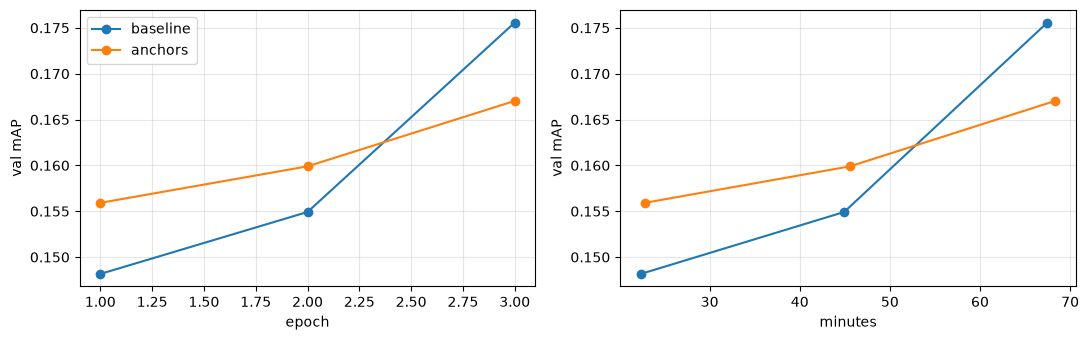

In [43]:
# Training curves and per-class AP
plot_history({s: json.load(open(ensure_run(s) / "history.json")) for s in ["baseline", "anchors"]})

**TODO: update after the anchors rerun.** **Findings.** The tuned model is the baseline with NMS 0.6, so it is no better than the baseline (mAP 0.176, AP50 0.366, AP_small 0.079, ~76 ms/img); neither experiment gave a gain beyond noise. Small objects are the weak point (AP_small 0.079 vs AP_large 0.347). Per-class AP is low for bus (0.087), motor (0.069) and bicycle (0.097) - the rare or small classes. Training had not converged: val mAP was still rising at epoch 3 (0.148 → 0.155 → 0.176), so a longer schedule is the most likely improvement.

## 8. What each stage contributes

- **RPN (first stage):** class-agnostic objectness on dense anchors; it proposes a few hundred to a few thousand candidate boxes. Its recall is the upper bound for the detector: an object without a proposal cannot be detected.
- **RoI head (second stage):** pools features for each proposal (RoIAlign), classifies it into the 8 classes or background, refines the box and removes duplicates with per-class NMS. It turns high-recall, low-precision proposals into few confident, labelled boxes.

Measured below: recall of the top-n proposals (class-agnostic, IoU ≥ 0.5) against the recall and box count of the final detections.

In [44]:
gt, det = match_errors(preds, final_cfg["image_ids"])
rpn = pd.read_csv(ensure_run("final") / "rpn_recall.csv", index_col=0)
found = gt.outcome.isin(["correct", "crowded", "wrong_class"])                 # GT covered by a final box (IoU >= 0.5, any class)
fin = found.groupby(gt.bucket.astype(str)).mean()
fin["all"] = found.mean()
rpn["final (score>=0.3)"] = fin
print(f"boxes per image: RPN {final_cfg['test']['proposals']} proposals -> final {len(det) / len(final_cfg['image_ids']):.0f} detections (score >= 0.3)")
rpn.round(3)

boxes per image: RPN 1000 proposals -> final 59 detections (score >= 0.3)


,top 100,top 300,top 1000,top 2000,final (score>=0.3)
bucket,,,,,
small,0.479,0.641,0.706,0.706,0.531
medium,0.567,0.716,0.815,0.822,0.672
large,0.802,0.925,0.986,0.989,0.949
all,0.577,0.725,0.813,0.818,0.676


**Findings.** The RPN is the ceiling: even with 1000 proposals it covers only 71% of small, 82% of medium and 99% of large objects (IoU ≥ 0.5), and going to 2000 adds almost nothing. The second stage then loses a further ~18 points on small objects (0.706 → 0.531) and ~14 on medium; for large it loses 4 points. It shrinks 1000 proposals to ~59 boxes per image and mostly fails on small or confusable objects, not on large ones. So small-object AP is limited by both stages: the RPN misses ~30% of them and the RoI head loses another ~18%.

## 9. Failure cases

Errors of the tuned model at score ≥ 0.3 and IoU 0.5: outcome of every GT box by size and occlusion, class confusions and the types of false positives.

GT outcomes: **correct** = detected with the right class; **crowded** = covered only by a box already used for a neighbour; **wrong_class** = detected as another class; **mislocalized** = best IoU 0.1–0.5; **missed** = no detection. Detections: **tp** = matches a GT box; **background** = on nothing; **ignored** = centre in an ignore region; **wrong_class** = right place, wrong class; **duplicate** = second box on an already matched GT.

outcome,correct,crowded,mislocalized,missed,wrong_class
size (% of GT),,,,,
small,45.9,0.6,22.6,24.3,6.6
medium,58.7,0.6,13.6,19.2,7.9
large,81.0,0.1,2.5,2.6,13.7


outcome,correct,crowded,mislocalized,missed,wrong_class
occlusion (% of GT),,,,,
0.000000,73.6,0.3,9.0,10.4,6.8
1.000000,52.2,0.5,18.0,19.1,10.1
2.000000,18.6,2.5,14.2,61.0,3.7


,detections,%
detection type,,
tp,22439,39.9
background,19043,33.9
ignored,6394,11.4
wrong_class,5722,10.2
duplicate,2617,4.7


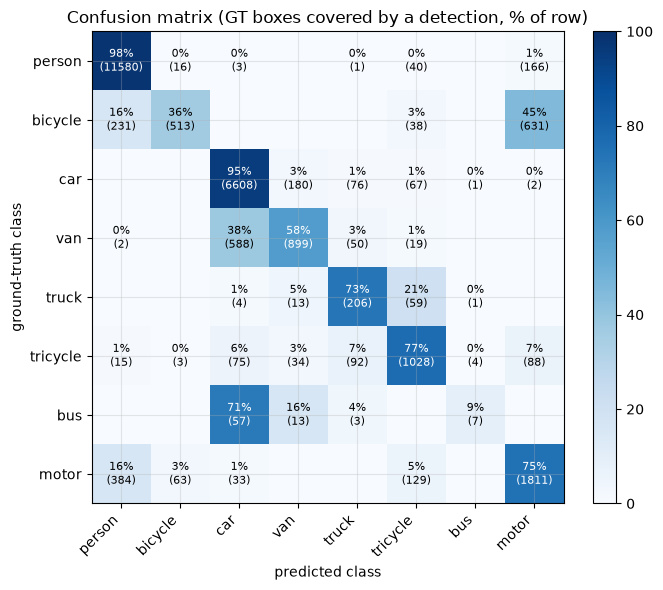

In [48]:
# GT outcome by size and occlusion, detection types, and the confusion matrix (helpers in utils/common.py)
error_tables(gt, det)
plot_confusion(gt);

Frames with the most missed small objects, the most class confusions and the most background false positives. Top: ground truth (box colour = class). Bottom: model predictions with score ≥ 0.3 (box colour = predicted class). Red areas are ignore regions.

In [ ]:
plot_failure_frames(gt, det, preds);

**Failure cases** (score ≥ 0.3, IoU 0.5):
1. **Small and occluded objects are missed or mislocalized.** Only 46% of small objects are correct (24% missed, 23% mislocalized) vs 81% of large ones. With heavy occlusion 61% are missed (73.6% correct with no occlusion). Likely cause: few pixels per object and weak features at the RPN's coarse levels; occluded objects look like background.
2. **Confusions between similar classes.** The largest are van → car (588), bicycle → motor (631), motor → person (384). Large objects have 13.7% wrong-class errors. Likely cause: similar appearance from above and few training examples of the rare class (bus, truck).
3. **Background false positives.** 19k of 56k detections at score ≥ 0.3 are on background (+6k in ignore regions, 2.6k duplicates). Likely causes: unlabeled objects and label noise (notebook 01, section 2.3), and ignore-region boundaries.
4. **What the example frames show.** Cars predicted as vans, traffic lights and similar street objects detected as vehicles or people (background false positives), several overlapping boxes on one object (duplicates), and detections on objects that have no label.
5. **Missing labels in the ground truth.** Some clearly visible objects outside the ignore regions have no GT box but are detected by the model. In the last example (parked cars at the top left) the cars are unlabeled in the ground truth but detected. Such detections are counted as false positives, so missing labels lower the measured precision and mAP, and they also teach the model to treat real objects as background during training.

## 10. Conclusion

**TODO: update after the anchors rerun.** Faster R-CNN reaches mAP 0.176, AP50 0.369, AP_small 0.079 at ~76 ms/img on val. Neither test-time proposals/NMS nor the data-driven anchors improved it beyond noise. The errors are mainly small, occluded and confusable objects, and the RPN (71% recall on small objects) limits what the second stage can do. For the next notebooks: this is the reference to compare against, a longer schedule is likely the cheapest gain, and small-object recall needs a higher input resolution or finer feature levels, not more proposals.